# Express Links · Week 1, step 5: bottleneck report

This notebook answers one question for METR-LA and PEMS-BAY: **are there real bottlenecks on the road graph, and how many road pairs sit across them?** Proposal 3.2 says we measure this **before training**: if the bottlenecks are weak, the synthetic data (toy city, Sharjah) carries the main conclusion.

**What it does, in the order of the plan**

1. Loads the R files from step 4 and splits each road graph into **regions** with a spectral partition, at every resolution from 2 to 8 regions (the plan asks us to fix this rule for "across a bottleneck").
2. Measures every region with one number, the **R jump**: how much harder it is to reach the region from the rest of the map than distance alone explains.
3. Calibrates the R jump on **reference towns** with 1, 2, 4 and 8 crossings between two districts (the layouts the toy city uses in step 8), so "strong" means "at least as narrow as a two-crossing town".
4. Keeps only bottlenecks that **hold up**: found at two or more resolutions, and above the line whether R uses the link weights or sets every link to 1.
5. Counts the sensors behind each bottleneck and the **road pairs across it**, states a **decision per benchmark: strong or weak**, draws the figures and writes the **one-page note** to `Coding/reports/bottleneck_report.md`.

**Run it:** Runtime → Run all. A **CPU runtime is enough**, no GPU and no training; about a minute. It needs the step 4 files.

**Output folders:** `Coding/data/processed/<dataset>/bottleneck/` (for later steps), `Coding/figures/` (figures), `Coding/reports/` (the note).

## Why this step matters (in plain words)

Step 4 gave every pair of roads a number R: how hard it is for information to travel between them. But a high R can mean two different things:

* **The roads are simply far apart.** Twelve road links in a row give a high R even on a perfect road. That is distance, and a deeper model can cover it.
* **The route squeezes through a narrow point**, such as one bridge. That is a **bottleneck**, and it is what over-squashing is about: information arrives blurred however deep the model is.

To tell them apart, compare like with like. For a region of the map:

> **R jump** = R between a road inside the region and a road outside it ÷ R between two roads on the *same side* that are the *same number of links apart*.

* **R jump ≈ 1:** getting in or out of the region costs nothing extra. Not a bottleneck, just distance.
* **R jump well above 1:** crossing costs much more than distance explains. **A bottleneck.**

**What "strong" means.** Two districts of 10 × 10 streets, joined by 1, 2, 4 or 8 crossings: the layouts the toy city uses for RQ1. A region is behind a **bottleneck** if its R jump is at least that of the **two-crossing** town; **mild** if it is between the four- and two-crossing towns. A benchmark has **strong bottlenecks** if at least one bottleneck holds up.

**How this differs from step 4**

| | Step 4 | Step 5 (this notebook) |
|---|---|---|
| Question | how hard is each pair to reach? | **is that because of a bottleneck, or just distance?** |
| Unit | one number per pair of roads | one verdict per region, one decision per benchmark |
| Output | the R table | the sensors behind each bottleneck, the decision, the one-page note |

**How it connects to the other steps**

| Step | What it uses from here |
|---|---|
| **Sunday meeting** | the decision: does METR-LA (and PEMS-BAY) carry the result, or does the synthetic data? (plan, risk table) |
| **9. Evaluation** | `behind_bottleneck`: the "roads behind a bottleneck" subset for jam recall and precision |
| **10. Same-side control** | `district`: two roads are "across a bottleneck" if their districts differ, "same side" if they match |
| **Report, section 4** | the one-page note, and the rule for "across a bottleneck" (the submission checklist asks for it) |

## 1. Connect Google Drive

Same cell as steps 3 and 4. Outside Colab, set `EXPRESS_LINKS_DIR` to your local copy of the `Coding` folder.

In [4]:
import os, sys, glob

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Find the shared 'Coding' folder. It works whether the folder is in your own Drive or is
    # your teammate's folder added to My Drive as a shortcut (Organize -> Add shortcut -> My Drive).
    FOLDER = os.path.join('AdvML_F26_Project_&_Survey_Paper', 'Project', 'Coding')
    ROOTS = ['/content/drive/MyDrive', '/content/drive/.shortcut-targets-by-id', '/content/drive/Shareddrives']
    hits = []
    for root in ROOTS:
        for depth in range(4):                      # the folder may sit up to 3 levels down
            hits += glob.glob(os.path.join(root, *(['*'] * depth), FOLDER))
    hits = sorted(set(h for h in hits if os.path.isdir(os.path.join(h, 'data'))), key=len)
    assert hits, ("Couldn't find the 'Coding' folder. In Google Drive open 'Shared with me', right-click "
                  "'AdvML_F26_Project_&_Survey_Paper' -> Organize -> Add shortcut -> My Drive, then rerun this cell.")
    PROJECT_DIR = hits[0]
else:
    PROJECT_DIR = os.environ.get('EXPRESS_LINKS_DIR', os.getcwd())
    assert os.path.isdir(os.path.join(PROJECT_DIR, 'data')), f'No data/ folder in {PROJECT_DIR}; set EXPRESS_LINKS_DIR.'
print('PROJECT_DIR =', PROJECT_DIR)

try:
    probe = os.path.join(PROJECT_DIR, '.write_test')
    open(probe, 'w').close(); os.remove(probe)
    print('OK  you can write to this folder')
except OSError:
    raise PermissionError('You can read this folder but not write to it. Ask the owner to share it with you as Editor.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR = /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding
OK  you can write to this folder


## 2. Settings

The rule is set here and the note repeats it word for word.

* `STRONG_CROSSINGS = 2` / `MILD_CROSSINGS = 4`: the bottleneck line is the two-crossing town; mild is between the four- and two-crossing towns.
* `MIN_RESOLUTIONS = 2` and `BOTH_WEIGHTINGS = True`: a bottleneck must **hold up**. It must be found at two or more resolutions (k), and it must pass the line both with R from step 4 (link weights as pipe widths) and with R where every link is 1. A region that passes only one way counts as mild.
* `LOCAL_SHARE = 0.10`: a bottleneck with fewer than 10% of the sensors behind it is reported as **local**: real, but it covers few roads, so a "behind the bottleneck" subset will be small.
* `K_RANGE = 2..8` regions; `MIN_REGION = 5` sensors (smaller pieces are dead ends, reported separately); `SAME_REGION = 0.8` (two regions found at different k count as the same if they share 80% of their sensors).
* `TOWN_SIZE = 10`: each reference district is a 10 × 10 street grid. If step 8 builds the toy city differently, change it here; the thresholds follow.

**How the rule was set.** The first pass of this notebook picked a single k (the largest eigengap). Its own robustness check showed that PEMS-BAY's answer flipped with k, because the two best k values were almost tied. The rule was therefore tightened to the multi-scale version above **before the final numbers were read**. The reference-town thresholds were not changed. The note says so.

In [5]:
import json, time
import numpy as np
import pandas as pd
from scipy.sparse.csgraph import connected_components, shortest_path

DATASETS = {
    'METR-LA':  dict(adj='adj_mx.pkl',     locations='graph_sensor_locations.csv'),
    'PEMS-BAY': dict(adj='adj_mx_bay.pkl', locations='graph_sensor_locations_bay.csv'),
}

# ---- The rule ----
STRONG_CROSSINGS = 2        # bottleneck = R jump at least that of a town with 2 crossings
MILD_CROSSINGS   = 4        # between the 4- and 2-crossing towns = mild
MIN_RESOLUTIONS  = 2        # must be found at >= 2 values of k
BOTH_WEIGHTINGS  = True     # must pass with weighted R and with every link = 1
LOCAL_SHARE      = 0.10     # under 10% of sensors behind the bottleneck = local
TOWN_SIZE        = 10       # reference districts are TOWN_SIZE x TOWN_SIZE street grids
TOWN_CROSSINGS   = [1, 2, 4, 8]
K_RANGE          = range(2, 9)
MIN_REGION       = 5        # smaller pieces are dead ends
SAME_REGION      = 0.8      # Jaccard overlap for "the same region found at another k"
MIN_PAIRS_PER_HOP = 10
KMEANS_RESTARTS  = 30
SEED             = 0

RAW_DIR  = os.path.join(PROJECT_DIR, 'data', 'raw')
OUT_ROOT = os.path.join(PROJECT_DIR, 'data', 'processed')
FIG_DIR  = os.path.join(PROJECT_DIR, 'figures')
REP_DIR  = os.path.join(PROJECT_DIR, 'reports')
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(REP_DIR, exist_ok=True)
for name in DATASETS:
    p = os.path.join(OUT_ROOT, name, 'resistance', 'resistance.npz')
    assert os.path.exists(p), f'Missing {p}. Run the step 4 notebook first.'
print('Step 4 files found for', ', '.join(DATASETS))
print('Outputs go to', os.path.join(OUT_ROOT, '<dataset>', 'bottleneck'), ',', FIG_DIR, 'and', REP_DIR)

# Same figure style as steps 2 to 4
import matplotlib.pyplot as plt
SERIES = ['#2a78d6', '#eb6834', '#1baf7a']          # categorical slots 1-3: main district, behind a bottleneck, mild
INK, SUBTLE, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': SUBTLE,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
})

Step 4 files found for METR-LA, PEMS-BAY
Outputs go to /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/processed/<dataset>/bottleneck , /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/figures and /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/reports


## 3. Load the step 4 files

From each `resistance.npz`: R with link weights as pipe widths, R with every link set to 1, the two-way graph W, the connected part of each sensor, and the number of links between every pair (hops). The checks confirm the file is complete and that R still passes Foster's theorem, so a damaged file is caught here and not three steps later.

The analysis uses the **main connected part** (206 of 207 sensors in METR-LA, 319 of 325 in PEMS-BAY). The cut-off sensors from step 4 have no links, so no boundary can be drawn around them; they are kept in the saved files with district `-1`.

In [6]:
def load_locations(name):
    path = os.path.join(RAW_DIR, DATASETS[name]['locations'])
    if name == 'METR-LA':
        loc = pd.read_csv(path)[['sensor_id', 'latitude', 'longitude']]
    else:                                       # the Bay Area file has no header row
        loc = pd.read_csv(path, header=None, names=['sensor_id', 'latitude', 'longitude'])
    loc['sensor_id'] = loc['sensor_id'].astype(str)
    return loc.set_index('sensor_id')

G = {}
for name in DATASETS:
    z = np.load(os.path.join(OUT_ROOT, name, 'resistance', 'resistance.npz'))
    ids = [str(s) for s in z['sensor_ids']]
    R, R_unw, W, comp, hops = z['R'], z['R_unweighted'], z['W'], z['component'], z['hops']
    sizes = np.bincount(comp)
    main = np.flatnonzero(comp == np.argmax(sizes))
    print(f'==== {name} ====')
    assert R.shape == W.shape == (len(ids), len(ids))
    Rm, Wm = R[np.ix_(main, main)], W[np.ix_(main, main)]
    assert np.all(np.isfinite(Rm)), 'R must be finite inside the main part'
    iu, iv = np.nonzero(np.triu(Wm > 0, 1))
    foster = (Wm[iu, iv] * Rm[iu, iv]).sum()
    assert np.isclose(foster, len(main) - 1, atol=1e-6), foster
    print(f'OK  {len(ids)} sensors; main part {len(main)}; R passes Foster ({foster:.4f} = {len(main) - 1})')
    G[name] = dict(ids=ids, main=main, R=Rm, R_unw=R_unw[np.ix_(main, main)], W=Wm,
                   hops=hops[np.ix_(main, main)].astype(int), loc=load_locations(name).reindex(ids),
                   n_all=len(ids), cut_off=[ids[i] for i in np.flatnonzero(sizes[comp] == 1)])
print()

==== METR-LA ====
OK  207 sensors; main part 206; R passes Foster (205.0000 = 205)
==== PEMS-BAY ====
OK  325 sensors; main part 319; R passes Foster (318.0000 = 318)



## 4. The tools

| Function | What it does |
|---|---|
| `spectral_regions(W, k)` | splits the graph into k regions: k-means on the first k eigenvectors of the normalised Laplacian (Ng, Jordan and Weiss, 2002), 30 restarts, fixed seed |
| `r_jump(R, hops, inside)` | the R jump of a region: for each hop distance h, median R of pairs with one road inside and one outside ÷ median R of pairs on the same side at distance h, averaged over h (weighted by the number of crossing pairs) |
| `candidate_regions(g)` | every region of 5 or more sensors (and at most half the map) at every k from 2 to 8, merged when the same region turns up at several k |
| `reference_town(c)` | two `TOWN_SIZE × TOWN_SIZE` street grids joined by `c` evenly spaced crossings |

The R jump compares pairs at the **same hop distance**, so it measures only the extra cost of crossing, not the distance itself. Section 5 checks that it behaves: it falls steadily from 1 crossing to 8, and is about 1 when the two districts are joined along their whole edge.

In [7]:
def resistance(W):
    '''Exact R on one connected graph (same method as step 4).'''
    n = len(W); L = np.diag(W.sum(1)) - W; J = np.full((n, n), 1.0 / n)
    Lp = np.linalg.inv(L + J) - J; d = np.diag(Lp)
    return np.maximum(d[:, None] + d[None, :] - 2 * Lp, 0)


def normalised_eigs(W):
    d = W.sum(1); s = 1 / np.sqrt(d)
    return np.linalg.eigh(np.eye(len(W)) - s[:, None] * W * s[None, :])


def kmeans(X, k, restarts=KMEANS_RESTARTS, seed=SEED, iters=100):
    '''Plain k-means++ with restarts (numpy only, same answer on every machine).'''
    rng = np.random.default_rng(seed); best = (np.inf, None)
    for _ in range(restarts):
        c = [X[rng.integers(len(X))]]
        for _ in range(k - 1):
            d2 = np.min(((X[:, None, :] - np.array(c)[None]) ** 2).sum(-1), 1)
            c.append(X[rng.choice(len(X), p=d2 / d2.sum())])
        c = np.array(c)
        for _ in range(iters):
            lab = np.argmin(((X[:, None, :] - c[None]) ** 2).sum(-1), 1)
            new = np.array([X[lab == j].mean(0) if np.any(lab == j) else c[j] for j in range(k)])
            if np.allclose(new, c): break
            c = new
        inertia = ((X - c[lab]) ** 2).sum()
        if inertia < best[0]: best = (inertia, lab)
    lab = best[1]
    order = np.argsort(-np.bincount(lab, minlength=k), kind='stable')   # region 0 = largest
    return np.argsort(order)[lab]


def spectral_regions(W, k):
    ev, vec = normalised_eigs(W)
    X = vec[:, :k] / np.linalg.norm(vec[:, :k], axis=1, keepdims=True)
    return kmeans(X, k)


def r_jump(R, hops, inside):
    '''R jump of a region (inside = True) against the rest. Returns (jump, per-hop table).'''
    iu = np.triu_indices(len(R), 1)
    r, h = R[iu], hops[iu]
    across = (inside[:, None] != inside[None, :])[iu]
    rows = []
    for hh in np.unique(h[across]):
        a, b = r[across & (h == hh)], r[~across & (h == hh)]
        if len(a) >= MIN_PAIRS_PER_HOP and len(b) >= MIN_PAIRS_PER_HOP:
            rows.append(dict(hops=int(hh), pairs_across=len(a), pairs_same_side=len(b),
                             median_R_across=float(np.median(a)), median_R_same_side=float(np.median(b)),
                             ratio=float(np.median(a) / np.median(b))))
    t = pd.DataFrame(rows)
    return (float(np.average(t.ratio, weights=t.pairs_across)) if len(t) else np.nan), t


def reference_town(c, n=TOWN_SIZE):
    N = 2 * n * n; W = np.zeros((N, N)); node = lambda d, i, j: d * n * n + i * n + j
    for d in range(2):
        for i in range(n):
            for j in range(n):
                if i + 1 < n: W[node(d, i, j), node(d, i + 1, j)] = 1
                if j + 1 < n: W[node(d, i, j), node(d, i, j + 1)] = 1
    rows = [n // 2] if c == 1 else np.unique(np.linspace(0, n - 1, c).round().astype(int))
    assert len(rows) == c, 'TOWN_SIZE too small for this many crossings'
    for i in rows:
        W[node(0, i, n - 1), node(1, i, 0)] = 1                         # east edge of A to west edge of B
    W = W + W.T
    return W, np.arange(N) < n * n


def jaccard(a, b):
    return (a & b).sum() / (a | b).sum()

print('OK  tools defined')

OK  tools defined


## 5. Reference towns: what "strong" means

Two districts of 10 × 10 streets, joined by 1, 2, 4 or 8 crossings. Their R jumps set the scale the benchmarks are judged on.

In [8]:
ref = {}
for c in TOWN_CROSSINGS:
    W_t, side_t = reference_town(c)
    H_t = shortest_path(W_t > 0, unweighted=True, directed=False).astype(int)
    ref[c], _ = r_jump(resistance(W_t), H_t, side_t)
    print(f'    {c} crossing(s): R jump {ref[c]:.2f}')

assert all(ref[a] > ref[b] for a, b in zip(TOWN_CROSSINGS, TOWN_CROSSINGS[1:])), 'R jump must fall as crossings are added'
print('OK  fewer crossings -> higher R jump')
W_open, side_open = reference_town(TOWN_SIZE)
open_jump, _ = r_jump(resistance(W_open), shortest_path(W_open > 0, unweighted=True, directed=False).astype(int), side_open)
assert abs(open_jump - 1) < 0.05, open_jump
print(f'OK  districts joined along the whole edge (no bottleneck): R jump {open_jump:.2f}, about 1')

THRESHOLD, MILD = ref[STRONG_CROSSINGS], ref[MILD_CROSSINGS]
print(f'\nRule: bottleneck if R jump >= {THRESHOLD:.2f} (the {STRONG_CROSSINGS}-crossing town); '
      f'mild if >= {MILD:.2f} ({MILD_CROSSINGS} crossings).')

def classify(jump_w, jump_u, n_k):
    worst = min(jump_w, jump_u) if BOTH_WEIGHTINGS else jump_w
    if n_k >= MIN_RESOLUTIONS and worst >= THRESHOLD: return 'bottleneck'
    if max(jump_w, jump_u) >= MILD: return 'mild'
    return 'none'

    1 crossing(s): R jump 1.80
    2 crossing(s): R jump 1.43
    4 crossing(s): R jump 1.13
    8 crossing(s): R jump 1.02
OK  fewer crossings -> higher R jump
OK  districts joined along the whole edge (no bottleneck): R jump 1.00, about 1

Rule: bottleneck if R jump >= 1.43 (the 2-crossing town); mild if >= 1.13 (4 crossings).


## 6. Every region at every resolution

For k = 2 to 8, the graph is split into k regions, and every region of 5 or more sensors (and at most half the map) becomes a candidate. The same region often turns up at several k; those copies are merged (80% of sensors in common), and the list of k where it appears says how **stable** it is.

Each candidate gets its R jump twice, with the step 4 link weights and with every link set to 1, plus the number of road links into it. The verdict follows the rule in section 2.

In [9]:
def candidate_regions(g):
    found = []
    for k in K_RANGE:
        reg = spectral_regions(g['W'], k)
        for rg in range(k):
            inside = reg == rg
            if MIN_REGION <= inside.sum() <= len(inside) / 2:
                found.append((k, inside))
    groups = []                                   # merge the same region found at several k
    for k, inside in found:
        for grp in groups:
            if jaccard(inside, grp['inside']) >= SAME_REGION:
                grp['ks'].append(k); break
        else:
            groups.append(dict(inside=inside, ks=[k]))
    rows = []
    for grp in groups:
        S = grp['inside']
        jw, _ = r_jump(g['R'], g['hops'], S)
        ju, _ = r_jump(g['R_unw'], g['hops'], S)
        loc = g['loc'].iloc[g['main'][S]]
        rows.append(dict(sensors=int(S.sum()), found_at_k=','.join(map(str, sorted(set(grp['ks'])))),
                         n_k=len(set(grp['ks'])), links_in=int((g['W'][np.ix_(S, ~S)] > 0).sum()),
                         R_jump=jw, R_jump_every_link_1=ju, verdict=classify(jw, ju, len(set(grp['ks']))),
                         lat=float(loc.latitude.mean()), lon=float(loc.longitude.mean())))
        grp.update(rows[-1])
    t = pd.DataFrame(rows).sort_values('R_jump', ascending=False).reset_index(drop=True)
    groups = sorted(groups, key=lambda x: -x['R_jump'])
    return t, groups

for name, g in G.items():
    t, groups = candidate_regions(g)
    g.update(candidates=t, groups=groups)
    print(f'==== {name}: {len(t)} distinct candidate regions ====')
    print(t.drop(columns=['lat', 'lon']).round(2).to_string(index=False))
    print()

==== METR-LA: 15 distinct candidate regions ====
 sensors found_at_k  n_k  links_in  R_jump  R_jump_every_link_1    verdict
       9  4,5,6,7,8    5         3    4.17                 2.57 bottleneck
      32          8    1        77    1.12                 1.05       none
      46      5,6,7    3        72    1.08                 1.03       none
      27          8    1        68    1.06                 1.08       none
      31      6,7,8    3        50    1.05                 1.04       none
      16          8    1        44    1.04                 1.06       none
      76      3,4,5    3        34    1.04                 1.01       none
      39      6,7,8    3        45    0.92                 0.92       none
      86        3,4    2        61    0.91                 0.91       none
      44    3,4,5,6    4        27    0.87                 0.95       none
      67          2    1        66    0.86                 0.92       none
      26        7,8    2        73    0.85         

## 7. Districts, sensors behind a bottleneck, and pairs across it

The bottleneck regions cut the map into **districts**: sensors are in the same district if they are on the same side of every bottleneck. Then:

* **sensors behind a bottleneck** = every sensor outside the largest district;
* **pairs across a bottleneck** = pairs of sensors in different districts.

The table per hop distance shows where the R jump comes from: a real bottleneck gives a high ratio already at short distances.

Also listed: **dead ends**, i.e. single links that are the only connection to 1 to 3 sensors (bridge score 1 in step 4). They are too small to be a district or to evaluate jams on, so they do not count as bottlenecks.

In [10]:
def km_between(loc, a, b):
    la1, lo1 = np.radians(loc['latitude'].values[a]), np.radians(loc['longitude'].values[a])
    la2, lo2 = np.radians(loc['latitude'].values[b]), np.radians(loc['longitude'].values[b])
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(h))

for name, g in G.items():
    R, W, H, N = g['R'], g['W'], g['hops'], len(g['R'])
    bott = [grp['inside'] for grp in g['groups'] if grp['verdict'] == 'bottleneck']
    mild = [grp['inside'] for grp in g['groups'] if grp['verdict'] == 'mild']
    sig = np.zeros((N, len(bott)), int)
    for b, S in enumerate(bott):
        sig[:, b] = S
    keys = {tuple(s) for s in sig}
    sizes = {kk: (sig == kk).all(1).sum() if len(bott) else N for kk in keys}
    order = sorted(keys, key=lambda kk: -sizes[kk])
    district = np.array([order.index(tuple(s)) for s in sig])
    behind = district > 0
    in_mild = np.any(mild, axis=0) & ~behind if mild else np.zeros(N, bool)
    iu = np.triu_indices(N, 1)
    across = (district[:, None] != district[None, :])[iu]
    g.update(district=district, behind=behind, in_mild=in_mild, across_mask=across)

    print(f'==== {name} ====')
    print(f'    bottlenecks: {len(bott)}; mild regions: {len(mild)}; districts: {district.max() + 1}')
    if behind.any():
        jump_d, table_d = r_jump(R, H, behind)
        cut = W[np.ix_(~behind, behind)]
        r = R[iu]
        g.update(links_into=int((cut > 0).sum()), district_table=table_d)
        print(f'    sensors behind a bottleneck: {behind.sum()} of {N} ({behind.mean():.1%})')
        print(f'    road links into them: {int((cut > 0).sum())} (total weight {cut.sum():.2f})')
        print(f'    pairs across a bottleneck: {across.sum():,} of {len(across):,} ({across.mean():.1%})')
        print(f'    median R across a bottleneck {np.median(r[across]):.2f} vs elsewhere {np.median(r[~across]):.2f}')
        print('\n    R jump by hop distance (across vs same side):')
        print(table_d.round(2).to_string(index=False))
        print('\n    the sensors behind the bottleneck:')
        print(g['loc'].iloc[g['main'][behind]][['latitude', 'longitude']].round(4).to_string())
    else:
        g.update(links_into=0, district_table=pd.DataFrame())
        print('    no bottleneck holds up: one district, no pairs across a bottleneck')
    if mild:
        print(f'    sensors in mild regions (not counted as behind a bottleneck): {in_mild.sum()}')

    bi, bj = np.nonzero(np.triu(W > 0, 1)); bs = W[bi, bj] * R[bi, bj]
    dead = []
    for i, j, b in zip(bi, bj, bs):
        if b > 0.999:
            Wc = W.copy(); Wc[i, j] = Wc[j, i] = 0
            _, lab = connected_components(Wc > 0, directed=False)
            small = np.flatnonzero(lab == np.argmin(np.bincount(lab)))
            dead.append(dict(link=f'{g["ids"][g["main"][i]]} - {g["ids"][g["main"][j]]}', sensors_cut_off=len(small),
                             sensor_ids=' '.join(g['ids'][g['main'][s]] for s in small),
                             km=float(km_between(g['loc'], g['main'][i], g['main'][j]))))
    g['dead_ends'] = pd.DataFrame(dead)
    assert not dead or g['dead_ends'].sensors_cut_off.max() < MIN_REGION, 'a true bridge cuts off a whole region: check it'
    print(f'\n    dead ends (a single link to 1-3 sensors): {len(dead)}')
    if dead:
        print(g['dead_ends'].round(2).to_string(index=False))
    print()

==== METR-LA ====
    bottlenecks: 1; mild regions: 0; districts: 2
    sensors behind a bottleneck: 9 of 206 (4.4%)
    road links into them: 3 (total weight 0.75)
    pairs across a bottleneck: 1,773 of 21,115 (8.4%)
    median R across a bottleneck 5.35 vs elsewhere 0.93

    R jump by hop distance (across vs same side):
 hops  pairs_across  pairs_same_side  median_R_across  median_R_same_side  ratio
    2            26             2358             3.25                0.58   5.63
    3            83             2564             4.65                0.73   6.35
    4           169             2683             4.88                0.86   5.68
    5           204             3012             5.07                0.96   5.28
    6           197             2853             5.29                1.07   4.93
    7           200             1769             5.32                1.36   3.92
    8           252             1153             5.36                1.58   3.40
    9           256       

## 8. How far is each benchmark from the line?

A decision near the line can flip with a small change in the rule. This table reruns the decision under neighbouring rules: a stricter and a looser line (the 1- and 4-crossing towns), each link weighting on its own, and a single-resolution version. A robust decision gives the same answer in most rows; a borderline one shows it.

In [11]:
def decide(t, line, weighting, min_k):
    jw, ju = t.R_jump.values, t.R_jump_every_link_1.values
    worst = {'both': np.minimum(jw, ju), 'weights': jw, 'every link = 1': ju}[weighting]
    ok = (worst >= line) & (t.n_k.values >= min_k)
    return ('strong' if ok.any() else 'weak'), (float(worst[ok].max()) if ok.any() else float(worst.max()))

variants = [('main rule', THRESHOLD, 'both', MIN_RESOLUTIONS),
            ('stricter line: 1-crossing town', ref[1], 'both', MIN_RESOLUTIONS),
            ('looser line: 4-crossing town', ref[4], 'both', MIN_RESOLUTIONS),
            ('link weights only', THRESHOLD, 'weights', MIN_RESOLUTIONS),
            ('every link = 1 only', THRESHOLD, 'every link = 1', MIN_RESOLUTIONS),
            ('any single resolution counts', THRESHOLD, 'both', 1)]
for name, g in G.items():
    rows = [dict(rule=v[0], line=v[1], decision=decide(g['candidates'], *v[1:])[0],
                 strongest_R_jump_used=decide(g['candidates'], *v[1:])[1]) for v in variants]
    rob = pd.DataFrame(rows)
    g['robustness'] = rob
    g['robust_agree'] = float((rob.decision == rob.decision.iloc[0]).mean())
    print(f'==== {name} ====')
    print(rob.round(2).to_string(index=False))
    print(f'    {g["robust_agree"]:.0%} of these rules give the main decision ({rob.decision.iloc[0]})\n')

==== METR-LA ====
                          rule  line decision  strongest_R_jump_used
                     main rule  1.43   strong                   2.57
stricter line: 1-crossing town  1.80   strong                   2.57
  looser line: 4-crossing town  1.13   strong                   2.57
             link weights only  1.43   strong                   4.17
           every link = 1 only  1.43   strong                   2.57
  any single resolution counts  1.43   strong                   2.57
    100% of these rules give the main decision (strong)

==== PEMS-BAY ====
                          rule  line decision  strongest_R_jump_used
                     main rule  1.43     weak                   1.22
stricter line: 1-crossing town  1.80     weak                   1.22
  looser line: 4-crossing town  1.13   strong                   1.22
             link weights only  1.43   strong                   1.44
           every link = 1 only  1.43     weak                   1.22
  any sin

## 9. The decision

The rule from section 2, applied as written:

* **Strong** if at least one bottleneck holds up; **weak** otherwise (with "borderline" if a mild region comes within 5% of the line).
* A strong bottleneck with under 10% of the sensors behind it is **strong, but local**.

What each decision means for the project follows the proposal (3.2) and the plan's risk table, and is printed with it.

In [12]:
decision = {}
for name, g in G.items():
    t = g['candidates']
    stable = t[t.n_k >= MIN_RESOLUTIONS] if (t.n_k >= MIN_RESOLUTIONS).any() else t
    worst = np.minimum(stable.R_jump, stable.R_jump_every_link_1)
    best = stable.loc[worst.idxmax()]                 # the stable candidate closest to (or furthest over) the line
    strong = bool((t.verdict == 'bottleneck').any())
    if strong:
        best = t[t.verdict == 'bottleneck'].iloc[0]
    n_behind, share = int(g['behind'].sum()), float(g['behind'].mean())
    jw, ju = float(best.R_jump), float(best.R_jump_every_link_1)
    stronger_than = [c for c in TOWN_CROSSINGS if min(jw, ju) >= ref[c]]
    like = (f'narrower than a {min(stronger_than)}-crossing town' if stronger_than
            else f'wider than a {max(TOWN_CROSSINGS)}-crossing town')
    local = strong and share < LOCAL_SHARE
    borderline = (not strong) and max(jw, ju) >= 0.95 * THRESHOLD
    if strong and local:
        label = 'Strong, but local'
        meaning = (f'{name} has one real bottleneck: {n_behind} sensors sit behind {g["links_into"]} road links, and reaching '
                   f'them costs {jw:.1f}x the R that distance explains ({ju:.1f}x with every link = 1; {like}). It is found '
                   f'at k = {best.found_at_k}. It covers only {share:.0%} of the sensors, so {name} can test RQ2 on real '
                   f'traffic, but the "behind the bottleneck" subset is small and its jam recall will be noisy. The toy '
                   f'city stays the main evidence for RQ1, and Sharjah should stay in the core plan.')
    elif strong:
        label = 'Strong'
        meaning = (f'{name} has bottlenecks covering {share:.0%} of the sensors; real-data results for RQ2 can carry the main '
                   f'conclusion alongside the toy city.')
    else:
        label = 'Weak (borderline)' if borderline else 'Weak'
        meaning = (f'No region of {name} passes the rule. The closest is a region of {int(best.sensors)} sensors at '
                   f'k = {best.found_at_k}: R jump {jw:.2f} with link weights, but {ju:.2f} with every link = 1 '
                   f'(line {THRESHOLD:.2f}). {name} has mild bottlenecks at most, comparable to a town with 2 to 4 crossings. '
                   f'As the proposal says, the synthetic data carries the main conclusion; {name} shows what express links '
                   f'do where bottlenecks are mild, and a gain as large as on a strong bottleneck would point to a cause '
                   f'other than over-squashing.')
    decision[name] = dict(label=label, meaning=meaning, strong=strong, local=local, borderline=borderline,
                          R_jump=jw, R_jump_every_link_1=ju, region_sensors=int(best.sensors), found_at_k=best.found_at_k,
                          like=like, sensors_behind=n_behind, share_behind=share, links_into=g['links_into'],
                          pairs_across=int(g['across_mask'].sum()), share_pairs_across=float(g['across_mask'].mean()),
                          mild_regions=int((t.verdict == 'mild').sum()), sensors_in_mild=int(g['in_mild'].sum()),
                          dead_ends=len(g['dead_ends']), robust_agree=g['robust_agree'])
    print(f'==== {name}: {label.upper()} ====')
    print('   ', meaning, '\n')

==== METR-LA: STRONG, BUT LOCAL ====
    METR-LA has one real bottleneck: 9 sensors sit behind 3 road links, and reaching them costs 4.2x the R that distance explains (2.6x with every link = 1; narrower than a 1-crossing town). It is found at k = 4,5,6,7,8. It covers only 4% of the sensors, so METR-LA can test RQ2 on real traffic, but the "behind the bottleneck" subset is small and its jam recall will be noisy. The toy city stays the main evidence for RQ1, and Sharjah should stay in the core plan. 

==== PEMS-BAY: WEAK (BORDERLINE) ====
    No region of PEMS-BAY passes the rule. The closest is a region of 23 sensors at k = 7,8: R jump 1.39 with link weights, but 1.22 with every link = 1 (line 1.43). PEMS-BAY has mild bottlenecks at most, comparable to a town with 2 to 4 crossings. As the proposal says, the synthetic data carries the main conclusion; PEMS-BAY shows what express links do where bottlenecks are mild, and a gain as large as on a strong bottleneck would point to a cause othe

## 10. Figures for the note

1. **The decision on one scale**: each benchmark's strongest region next to the four reference towns, with link weights (filled dot) and with every link = 1 (open dot). Right of the dashed line = bottleneck.
2. **Where R comes from**: the step 4 R distribution, with pairs across a bottleneck in orange. If the bottleneck explains the high-R pairs, they sit in the orange part.
3. **Map**: sensors behind a bottleneck in orange (links into them in black), sensors in mild regions in green, everything else in blue.

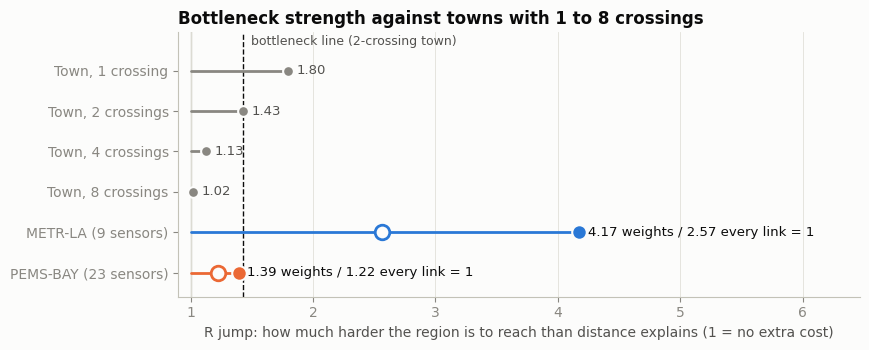

In [13]:
# ---- Figure 1: the decision scale ----
rows = [(f'Town, {c} crossing' + ('s' if c > 1 else ''), ref[c], None, None) for c in TOWN_CROSSINGS]
for i, (n, d) in enumerate(decision.items()):
    rows.append((f'{n} ({d["region_sensors"]} sensors)', d['R_jump'], d['R_jump_every_link_1'], SERIES[i]))
fig, ax = plt.subplots(figsize=(8.8, 3.6))
for y, (lab, val, val_u, color) in enumerate(rows[::-1]):
    if color is None:
        ax.plot([1, val], [y, y], color=MUTED, lw=2, solid_capstyle='round', zorder=2)
        ax.scatter(val, y, s=60, color=MUTED, zorder=3, edgecolor='#fcfcfb', lw=1.5)
        ax.text(val + 0.07, y, f'{val:.2f}', va='center', fontsize=9.5, color=SUBTLE)
    else:
        lo, hi = sorted([val, val_u])
        ax.plot([1, hi], [y, y], color=color, lw=2, solid_capstyle='round', zorder=2)
        ax.scatter(val, y, s=110, color=color, zorder=4, edgecolor='#fcfcfb', lw=1.5)
        ax.scatter(val_u, y, s=110, facecolor='#fcfcfb', edgecolor=color, lw=2, zorder=4)
        ax.text(hi + 0.07, y, f'{val:.2f} weights / {val_u:.2f} every link = 1', va='center', fontsize=9.5, color=INK)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows[::-1]])
ax.axvline(THRESHOLD, color=INK, lw=1, ls='--', zorder=1)
ax.text(THRESHOLD, len(rows) - 0.45, f'  bottleneck line ({STRONG_CROSSINGS}-crossing town)', fontsize=9, color=SUBTLE, va='bottom')
ax.axvline(1, color='#c3c2b7', lw=1, zorder=1)
xmax = max(max(r[1], r[2] or 0) for r in rows)
ax.set_xlim(0.9, xmax * 1.55); ax.set_ylim(-0.6, len(rows) - 0.05)
ax.set_xlabel('R jump: how much harder the region is to reach than distance explains (1 = no extra cost)')
ax.grid(axis='y', visible=False)
ax.set_title('Bottleneck strength against towns with 1 to 8 crossings', loc='left')
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'bottleneck_scale.png'), dpi=170, bbox_inches='tight'); plt.show()

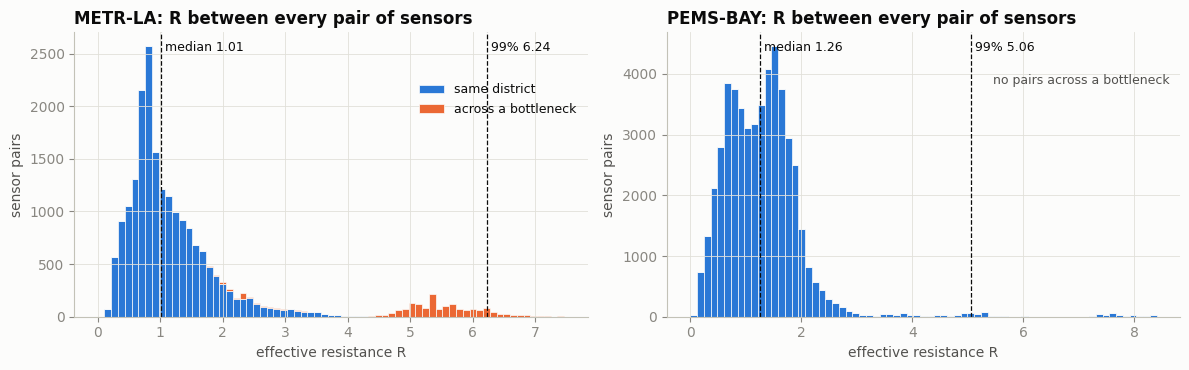

In [14]:
# ---- Figure 2: R distribution, pairs across a bottleneck highlighted ----
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, g) in zip(axes, G.items()):
    r = g['R'][np.triu_indices(len(g['R']), 1)]; m = g['across_mask']
    bins = np.linspace(0, np.percentile(r, 99.9), 70)
    ax.hist([r[~m], r[m]], bins=bins, stacked=True, color=[SERIES[0], SERIES[1]],
            edgecolor='#fcfcfb', linewidth=0.5, label=['same district', 'across a bottleneck'])
    med, p99 = np.median(r), np.percentile(r, 99)
    for v, lab in [(med, 'median'), (p99, '99%')]:
        ax.axvline(v, color=INK, lw=0.9, ls='--')
        ax.text(v, ax.get_ylim()[1] * 0.97, f' {lab} {v:.2f}', fontsize=9, va='top')
    ax.set_title(f'{name}: R between every pair of sensors', loc='left')
    ax.set_xlabel('effective resistance R'); ax.set_ylabel('sensor pairs')
    if m.any():
        ax.legend(frameon=False, fontsize=9, loc='upper right', bbox_to_anchor=(1, 0.86))
    else:
        ax.text(0.98, 0.82, 'no pairs across a bottleneck', transform=ax.transAxes, ha='right', fontsize=9, color=SUBTLE)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'bottleneck_R_distribution.png'), dpi=170, bbox_inches='tight'); plt.show()

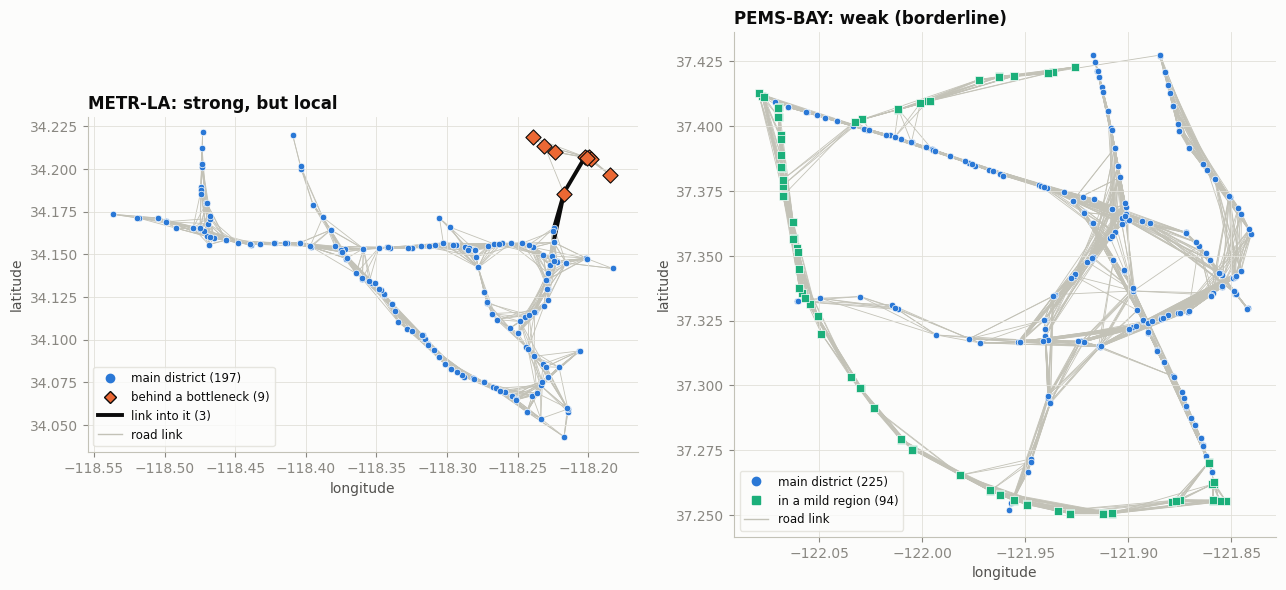

In [15]:
# ---- Figure 3: map ----
from matplotlib.lines import Line2D
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
for ax, (name, g) in zip(axes, G.items()):
    loc = g['loc'].iloc[g['main']]; lat, lon = loc['latitude'].values, loc['longitude'].values
    W, district, behind, mild = g['W'], g['district'], g['behind'], g['in_mild']
    for i, j in zip(*np.nonzero(np.triu(W > 0, 1))):
        if district[i] != district[j]:
            ax.plot([lon[i], lon[j]], [lat[i], lat[j]], color=INK, lw=2.8, zorder=3, solid_capstyle='round')
        else:
            ax.plot([lon[i], lon[j]], [lat[i], lat[j]], color='#c3c2b7', lw=0.6, zorder=1)
    other = ~behind & ~mild
    ax.scatter(lon[other], lat[other], s=22, color=SERIES[0], edgecolor='#fcfcfb', lw=0.5, zorder=4)
    ax.scatter(lon[mild], lat[mild], s=30, marker='s', color=SERIES[2], edgecolor='#fcfcfb', lw=0.5, zorder=4)
    ax.scatter(lon[behind], lat[behind], s=60, marker='D', color=SERIES[1], edgecolor=INK, lw=0.8, zorder=5)
    handles = [Line2D([], [], ls='', marker='o', color=SERIES[0], label=f'main district ({other.sum()})')]
    if mild.any():
        handles.append(Line2D([], [], ls='', marker='s', color=SERIES[2], label=f'in a mild region ({mild.sum()})'))
    if behind.any():
        handles += [Line2D([], [], ls='', marker='D', color=SERIES[1], markeredgecolor=INK, label=f'behind a bottleneck ({behind.sum()})'),
                    Line2D([], [], color=INK, lw=2.8, label=f'link into it ({g["links_into"]})')]
    handles.append(Line2D([], [], color='#c3c2b7', lw=1, label='road link'))
    ax.legend(handles=handles, loc='lower left', fontsize=8.5, frameon=True, facecolor='#fcfcfb', edgecolor=GRID)
    ax.set_aspect(1 / np.cos(np.radians(lat.mean())))
    ax.set_title(f'{name}: {decision[name]["label"].lower()}', loc='left')
    ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'bottleneck_map.png'), dpi=170, bbox_inches='tight'); plt.show()

In [16]:
# ---- Interactive map (open from Coding/figures/ in a browser) ----
!pip -q install folium
import folium
from IPython.display import display
TILES = 'https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}'
ATTR = 'Tiles &copy; Esri &mdash; Esri, DeLorme, NAVTEQ'

def bottleneck_map(name):
    g = G[name]; loc = g['loc'].iloc[g['main']]; lat, lon = loc['latitude'].values, loc['longitude'].values
    ids = [g['ids'][i] for i in g['main']]; W, district = g['W'], g['district']
    m = folium.Map(tiles=TILES, attr=ATTR, max_zoom=16, control_scale=True)
    m.fit_bounds([[lat.min(), lon.min()], [lat.max(), lon.max()]], padding=(20, 20))
    for i, j in zip(*np.nonzero(np.triu(W > 0, 1))):
        across = district[i] != district[j]
        folium.PolyLine([[lat[i], lon[i]], [lat[j], lon[j]]], color=INK if across else '#a8a69e',
                        weight=4 if across else 1, opacity=0.9 if across else 0.6,
                        tooltip=f'link into the bottleneck: {ids[i]} - {ids[j]}' if across else None).add_to(m)
    for i in range(len(ids)):
        kind = 'behind a bottleneck' if g['behind'][i] else ('in a mild region' if g['in_mild'][i] else 'main district')
        color = SERIES[1] if g['behind'][i] else (SERIES[2] if g['in_mild'][i] else SERIES[0])
        folium.CircleMarker([lat[i], lon[i]], radius=7 if g['behind'][i] else 5, color='#52514e', weight=0.8,
                            fill=True, fill_opacity=0.95, fill_color=color,
                            tooltip=f'<b>{name} sensor {ids[i]}</b><br>{kind}').add_to(m)
    m.save(os.path.join(FIG_DIR, f'bottleneck_map_{name}.html'))
    return m

maps = {n: bottleneck_map(n) for n in G}
print('Saved interactive maps:', [f'bottleneck_map_{n}.html' for n in maps])
display(maps['METR-LA'])

Saved interactive maps: ['bottleneck_map_METR-LA.html', 'bottleneck_map_PEMS-BAY.html']


## 11. Save the files

One folder per dataset, `Coding/data/processed/<dataset>/bottleneck/`:

| File | Contents | Used by |
|---|---|---|
| `regions.npz` | for **all** sensors, in the speed-data order: `district` (−1 = cut off), `behind_bottleneck`, `in_mild_region` (bools), `sensor_ids` | steps 9, 10 |
| `candidates.csv` | the section 6 table | report |
| `robustness.csv` | the section 8 table | report |
| `dead_ends.csv` | the dead-end links | report |
| `summary.json` | the decision and its numbers | note, report |

In [17]:
for name, g in G.items():
    out = os.path.join(OUT_ROOT, name, 'bottleneck'); os.makedirs(out, exist_ok=True)
    N = g['n_all']
    district_all = np.full(N, -1); behind_all = np.zeros(N, bool); mild_all = np.zeros(N, bool)
    district_all[g['main']] = g['district']; behind_all[g['main']] = g['behind']; mild_all[g['main']] = g['in_mild']
    np.savez_compressed(os.path.join(out, 'regions.npz'), district=district_all, behind_bottleneck=behind_all,
                        in_mild_region=mild_all, sensor_ids=np.array(g['ids']))
    g['candidates'].to_csv(os.path.join(out, 'candidates.csv'), index=False)
    g['robustness'].to_csv(os.path.join(out, 'robustness.csv'), index=False)
    g['dead_ends'].to_csv(os.path.join(out, 'dead_ends.csv'), index=False)
    d = dict(decision[name]); d.update(reference_R_jump={str(c): ref[c] for c in ref}, threshold=THRESHOLD,
                                       rule=(f'R jump >= {STRONG_CROSSINGS}-crossing town with both weightings, '
                                             f'found at >= {MIN_RESOLUTIONS} of k = 2..8'),
                                       cut_off_sensors=g['cut_off'],
                                       sensors_behind_ids=[g['ids'][i] for i in g['main'][g['behind']]])
    with open(os.path.join(out, 'summary.json'), 'w') as f:
        json.dump(d, f, indent=2)

    z = np.load(os.path.join(out, 'regions.npz'))
    assert list(z['sensor_ids']) == g['ids'] and z['behind_bottleneck'].sum() == g['behind'].sum()
    assert np.all((z['district'] == -1) == ~np.isin(np.arange(N), g['main']))
    print(f'OK  {name}: saved and reloaded {out}')
    for fn in sorted(os.listdir(out)):
        print(f'      {fn:18s} {os.path.getsize(os.path.join(out, fn)) / 1e3:7.1f} kB')

OK  METR-LA: saved and reloaded /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/processed/METR-LA/bottleneck
      candidates.csv         1.5 kB
      dead_ends.csv          0.0 kB
      regions.npz            1.7 kB
      robustness.csv         0.4 kB
      summary.json           1.4 kB
OK  PEMS-BAY: saved and reloaded /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/processed/PEMS-BAY/bottleneck
      candidates.csv         1.5 kB
      dead_ends.csv          0.2 kB
      regions.npz            1.9 kB
      robustness.csv         0.4 kB
      summary.json           1.4 kB


## 12. The one-page note

Written to `Coding/reports/bottleneck_report.md`, with the three figures in `Coding/figures/`. It is generated from the numbers above, so rerunning the notebook keeps it in sync.

In [18]:
def pct(x): return f'{x:.1%}' if x < 0.1 else f'{x:.0%}'

L = ['# Bottleneck report: METR-LA and PEMS-BAY (Week 1, step 5)', '',
     '**Question (proposal 3.2):** are the bottlenecks in each benchmark strong enough for real-data results to carry the '
     'conclusion, or does the synthetic data carry it?', '',
     '## Decision', '', '| | Decision | Why |', '|---|---|---|']
for n, d in decision.items():
    why = (f'{d["sensors_behind"]} sensors ({pct(d["share_behind"])}) behind {d["links_into"]} links; R jump '
           f'{d["R_jump"]:.2f} ({d["R_jump_every_link_1"]:.2f} with every link = 1), {d["like"]}' if d['strong']
           else f'closest region ({d["region_sensors"]} sensors): R jump {d["R_jump"]:.2f}, but '
                f'{d["R_jump_every_link_1"]:.2f} with every link = 1; line {THRESHOLD:.2f}')
    L.append(f'| **{n}** | **{d["label"]}** | {why} |')
L += ['', '## The numbers', '', '| | ' + ' | '.join(G) + ' |', '|---|' + '---|' * len(G)]
def row(lbl, f): L.append(f'| {lbl} | ' + ' | '.join(f(n) for n in G) + ' |')
Rs = {n: G[n]['R'][np.triu_indices(len(G[n]['R']), 1)] for n in G}
row('Sensors analysed (main part)', lambda n: f'{len(G[n]["main"])} of {G[n]["n_all"]}')
row('R: median / 99th percentile / max', lambda n: f'{np.median(Rs[n]):.2f} / {np.percentile(Rs[n], 99):.2f} / {Rs[n].max():.2f}')
row('Candidate regions (k = 2 to 8)', lambda n: str(len(G[n]['candidates'])))
row('Bottleneck / mild / none', lambda n: ' / '.join(str(int((G[n]['candidates'].verdict == v).sum())) for v in ['bottleneck', 'mild', 'none']))
row('Strongest region: R jump (weights / every link = 1)', lambda n: f'{decision[n]["R_jump"]:.2f} / {decision[n]["R_jump_every_link_1"]:.2f}')
row('Sensors behind a bottleneck', lambda n: f'{decision[n]["sensors_behind"]} ({pct(decision[n]["share_behind"])})')
row('Road pairs across a bottleneck', lambda n: f'{decision[n]["pairs_across"]:,} ({pct(decision[n]["share_pairs_across"])})')
row('Dead ends (single link to 1-3 sensors)', lambda n: str(decision[n]['dead_ends']))
row('Same decision under neighbouring rules', lambda n: f'{decision[n]["robust_agree"]:.0%} of 6')
L += ['', '![Decision scale](../figures/bottleneck_scale.png)', '',
      '![R distribution](../figures/bottleneck_R_distribution.png)', '',
      '![Bottleneck map](../figures/bottleneck_map.png)', '',
      '## What it means for the project', '']
L += [f'- **{n}:** {d["meaning"]}' for n, d in decision.items()]
L += ['', '## Method (state in the report)', '',
      '- **R jump** of a region = median R of pairs with one road inside and one outside, divided by median R of pairs on '
      'the same side at the same number of road links, averaged over hop distances. It measures the extra cost of '
      'crossing, not distance.',
      f'- **Regions:** spectral partition of the two-way road graph (normalised Laplacian, k-means with {KMEANS_RESTARTS} '
      f'restarts, seed {SEED}) at every k from 2 to 8; regions of {MIN_REGION} or more sensors and at most half the map.',
      f'- **Rule:** a region is behind a bottleneck if its R jump is at least that of a town of two {TOWN_SIZE} x '
      f'{TOWN_SIZE} districts joined by {STRONG_CROSSINGS} crossings (R jump {THRESHOLD:.2f}; 1 crossing {ref[1]:.2f}, '
      f'4 crossings {ref[4]:.2f}, 8 crossings {ref[8]:.2f}), with both link weightings, at {MIN_RESOLUTIONS} or more '
      f'values of k. A benchmark is strong if any region passes; local if under {LOCAL_SHARE:.0%} of its sensors are behind it.',
      '- **How the rule was set:** a first pass used one k (the largest eigengap); its robustness check showed PEMS-BAY '
      'flipping with k, so the rule was tightened to the multi-scale version before the final numbers were read. The '
      'reference-town thresholds were not changed.',
      '- **"Across a bottleneck"** (same-side control, behind-bottleneck subset): two roads are across a bottleneck if '
      'they are in different districts, i.e. on different sides of a bottleneck region. Saved as `district` and '
      '`behind_bottleneck` in `data/processed/<dataset>/bottleneck/regions.npz`.',
      '- Road map only, no speed data, so no test information is used.']
note = '\n'.join(L)
with open(os.path.join(REP_DIR, 'bottleneck_report.md'), 'w') as f:
    f.write(note)
with open(os.path.join(REP_DIR, 'bottleneck_report.json'), 'w') as f:
    json.dump(decision, f, indent=2)
from IPython.display import Markdown
display(Markdown(note.replace('../figures/', 'file://' + FIG_DIR + '/')))
print('Saved', os.path.join(REP_DIR, 'bottleneck_report.md'))

# Bottleneck report: METR-LA and PEMS-BAY (Week 1, step 5)

**Question (proposal 3.2):** are the bottlenecks in each benchmark strong enough for real-data results to carry the conclusion, or does the synthetic data carry it?

## Decision

| | Decision | Why |
|---|---|---|
| **METR-LA** | **Strong, but local** | 9 sensors (4.4%) behind 3 links; R jump 4.17 (2.57 with every link = 1), narrower than a 1-crossing town |
| **PEMS-BAY** | **Weak (borderline)** | closest region (23 sensors): R jump 1.39, but 1.22 with every link = 1; line 1.43 |

## The numbers

| | METR-LA | PEMS-BAY |
|---|---|---|
| Sensors analysed (main part) | 206 of 207 | 319 of 325 |
| R: median / 99th percentile / max | 1.01 / 6.24 / 8.92 | 1.26 / 5.06 / 12.03 |
| Candidate regions (k = 2 to 8) | 15 | 15 |
| Bottleneck / mild / none | 1 / 0 / 14 | 0 / 8 / 7 |
| Strongest region: R jump (weights / every link = 1) | 4.17 / 2.57 | 1.39 / 1.22 |
| Sensors behind a bottleneck | 9 (4.4%) | 0 (0.0%) |
| Road pairs across a bottleneck | 1,773 (8.4%) | 0 (0.0%) |
| Dead ends (single link to 1-3 sensors) | 0 | 3 |
| Same decision under neighbouring rules | 100% of 6 | 67% of 6 |

![Decision scale](file:///content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/figures/bottleneck_scale.png)

![R distribution](file:///content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/figures/bottleneck_R_distribution.png)

![Bottleneck map](file:///content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/figures/bottleneck_map.png)

## What it means for the project

- **METR-LA:** METR-LA has one real bottleneck: 9 sensors sit behind 3 road links, and reaching them costs 4.2x the R that distance explains (2.6x with every link = 1; narrower than a 1-crossing town). It is found at k = 4,5,6,7,8. It covers only 4% of the sensors, so METR-LA can test RQ2 on real traffic, but the "behind the bottleneck" subset is small and its jam recall will be noisy. The toy city stays the main evidence for RQ1, and Sharjah should stay in the core plan.
- **PEMS-BAY:** No region of PEMS-BAY passes the rule. The closest is a region of 23 sensors at k = 7,8: R jump 1.39 with link weights, but 1.22 with every link = 1 (line 1.43). PEMS-BAY has mild bottlenecks at most, comparable to a town with 2 to 4 crossings. As the proposal says, the synthetic data carries the main conclusion; PEMS-BAY shows what express links do where bottlenecks are mild, and a gain as large as on a strong bottleneck would point to a cause other than over-squashing.

## Method (state in the report)

- **R jump** of a region = median R of pairs with one road inside and one outside, divided by median R of pairs on the same side at the same number of road links, averaged over hop distances. It measures the extra cost of crossing, not distance.
- **Regions:** spectral partition of the two-way road graph (normalised Laplacian, k-means with 30 restarts, seed 0) at every k from 2 to 8; regions of 5 or more sensors and at most half the map.
- **Rule:** a region is behind a bottleneck if its R jump is at least that of a town of two 10 x 10 districts joined by 2 crossings (R jump 1.43; 1 crossing 1.80, 4 crossings 1.13, 8 crossings 1.02), with both link weightings, at 2 or more values of k. A benchmark is strong if any region passes; local if under 10% of its sensors are behind it.
- **How the rule was set:** a first pass used one k (the largest eigengap); its robustness check showed PEMS-BAY flipping with k, so the rule was tightened to the multi-scale version before the final numbers were read. The reference-town thresholds were not changed.
- **"Across a bottleneck"** (same-side control, behind-bottleneck subset): two roads are across a bottleneck if they are in different districts, i.e. on different sides of a bottleneck region. Saved as `district` and `behind_bottleneck` in `data/processed/<dataset>/bottleneck/regions.npz`.
- Road map only, no speed data, so no test information is used.

Saved /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/reports/bottleneck_report.md


## Done

Step 5 is done when this notebook has run and `Coding/reports/bottleneck_report.md` exists. Together with the step 3 baseline, that closes **week 1** ("Done when: the baseline trains and the bottleneck report exists").

* **Bring the decision table to the Sunday meeting.** It answers the plan's risk-table question: does METR-LA carry the result, and should Sharjah move from stretch to core?
* **Step 9** reads `behind_bottleneck` for the "roads behind a bottleneck" subset. Where a benchmark has no bottleneck, that subset is empty: report all roads (and, if useful, `in_mild_region` as a secondary subset, labelled as mild).
* **Step 10** reads `district` for the same-side control: a same-side link joins two roads in the same district.
* **If an `assert` fails in section 3:** rerun step 4. **In section 5:** the reference towns were changed in a way that breaks the measure; restore `TOWN_SIZE` and `TOWN_CROSSINGS`.